# **Symbolic Regression with Genetic Programming**

In this notebook we will look at **Symbolic Regression with Genetic Programming**.

Install **gplearn** library for Genetic Programming. It's usage is very similar to **scikit-learn** usage.

In [1]:
!pip install gplearn


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
%pip install --upgrade --force-reinstall scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 37.8 MB/s  0:00:00
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Uninstalling threadpoolctl-3.7.0:
      Successfully uninstalled threadpoolctl-3.7.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.3
    Uninstalling numpy-2.5.3:
      Successfully uninstalled numpy-2.5.3
  Attempting uninstall: narwhals━━━━━━━━━━━━━━━━━

Do our imports.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import graphviz

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate

Import `SymbolicRegressor` for regression.

In [4]:
from gplearn.genetic import SymbolicRegressor

Mount Google Drive so that we can load our dataset.

In [5]:
# from google.colab import drive
# drive.mount('/content/drive')

Load the data.

In [6]:
data = pd.read_csv('./auto-lpkm.tsv', sep='\t', header=0)
data

,id,cylinders,displacement,horsepower,weight_lbs,weight_kg,acceleration,model_year,color,more_info_1,more_info_2,more_info_3,more_info_4,more_info_5,l100km
0,0,4,98.0,79,2255,1023,17.7,76,1,94,91,49,97,68,9.0
1,1,4,113.0,95,2278,1033,15.5,72,4,97,58,66,85,38,9.8
2,2,8,351.0,153,4129,1873,13.0,72,1,41,8,15,83,70,16.8
3,3,4,97.0,88,2279,1034,19.0,73,2,53,3,42,2,82,11.8
4,4,6,199.0,97,2774,1258,15.5,70,0,74,53,24,51,53,13.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,195,4,91.0,67,1995,905,16.2,82,4,48,61,22,29,3,6.2
196,196,4,140.0,90,2408,1092,19.5,72,3,81,43,46,100,13,11.8
197,197,4,135.0,84,2370,1075,13.0,82,2,32,57,13,52,6,6.5
198,198,4,91.0,68,2025,918,18.2,82,4,55,88,70,53,54,6.4


The last column is the $y$, i.e., liters per 100 km which we must learn to predict.

In [7]:
X = data.to_numpy()[:, 0:-1]
y = data.to_numpy()[:, -1]
data = data.drop('l100km', axis=1)
feature_names = data.columns.values

Build the regression model.

In [8]:
# https://gplearn.readthedocs.io/en/stable/reference.html
# https://github.com/trevorstephens/gplearn/blob/main/doc/gp_examples.ipynb

model = SymbolicRegressor(population_size=200,    # number of individuals in a population
                          generations=20,         # number of iterations
                          init_depth=(2,6),       # min and max tree sizes for primordial soup
                          const_range=(-10,10),   # range of values for constants in a tree
                          metric='mse',           # measure to optimize for
                          function_set=('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv'),
                          stopping_criteria=0.01, # a little penalty for tree complexity
                          p_crossover=0.75,       # crossover probability
                          p_subtree_mutation=0.1, # subtree mutation probability
                          p_point_mutation=0.1,   # separate leaf mutation probability
                          max_samples=1,          # how many samples to use for training
                          feature_names=feature_names,
                          random_state=42,
                          verbose=1)
model = make_pipeline(StandardScaler(), model)
model.fit(X, y)

    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    10.87          94931.3        3           15.446              N/A      0.87s
   1     9.83          316.888        3           15.446              N/A      0.68s
   2     6.89           588.26       10          9.23746              N/A      0.72s
   3     4.79          56.2143       10           5.6046              N/A      0.66s
   4     7.85          109.574       12          3.59535              N/A      0.57s
   5    11.01          61.5157       20          3.22549              N/A      0.67s
   6    12.79          86.2918       18          3.08355              N/A      0.57s
   7    14.56          57.4533       16          3.08355              N/A      0.50s
   8    18.72          59.5184       31          3.05934              N/A  

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('symbolicregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](14,)","[ 99.5 , 5.33,186.15,..., 47.23, 46.69, 51.25]"


Print the built model.

In [9]:
print(model[-1]._program)

inv(inv(add(add(inv(inv(add(sqrt(add(add(inv(inv(add(sqrt(sub(add(sqrt(sub(sub(weight_lbs, -3.757), -3.757)), sub(sub(horsepower, model_year), -3.757)), -3.757)), mul(sqrt(sub(sub(weight_lbs, -3.757), model_year)), sub(sub(weight_lbs, -3.757), -3.757))))), weight_kg), horsepower)), sub(sub(horsepower, -3.757), -3.757)))), weight_kg), weight_kg)))


Plot the built model.

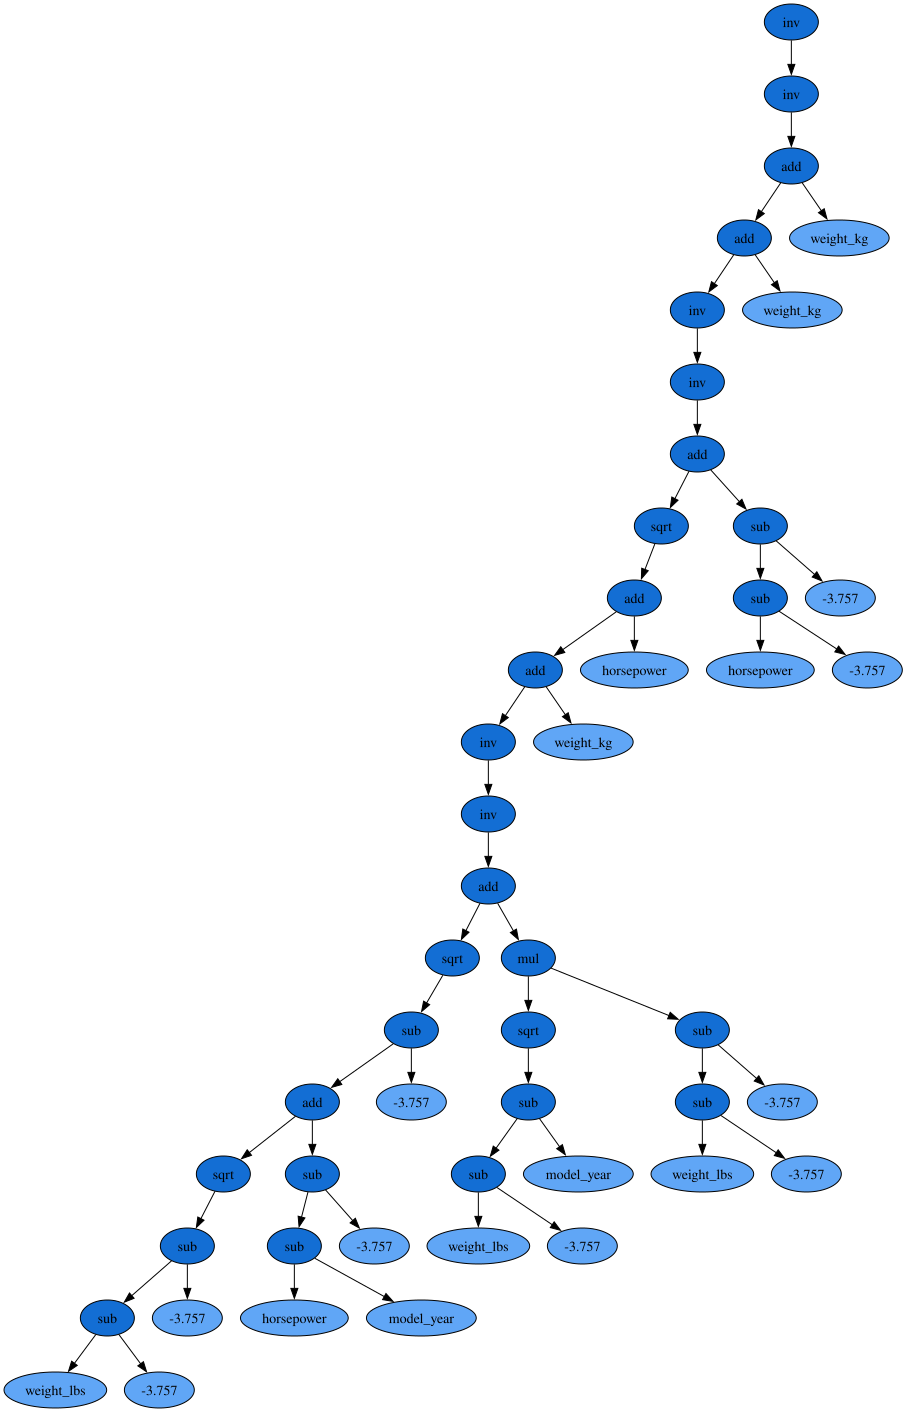

In [11]:
dot_data = model[-1]._program.export_graphviz()
graph = graphviz.Source(dot_data)
graph

Evaluate the algorithm using Cross-Validation.

In [12]:
model = SymbolicRegressor(population_size=200,
                          generations=20,
                          init_depth=(2,6),
                          const_range=(-10,10),
                          metric='mse',
                          function_set=('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv'),
                          stopping_criteria=0.01,
                          p_crossover=0.75,
                          p_subtree_mutation=0.1,
                          p_point_mutation=0.1,
                          max_samples=1,
                          feature_names=feature_names,
                          random_state=42)
model = make_pipeline(StandardScaler(), model)

R2 = cross_validate(model, X, y, cv=10, scoring=["r2"])['test_r2'].mean()
print('R2: %.3f' % R2)

R2: 0.803


<br>
<br>
<br>
<br>
<br>
<br>

---
<small>*Notebook by Gints Jēkabsons*</small>